# Токенизатор: byte-level BPE на FineWeb-2 rus

Baseline из плана эксперимента. Алгоритм — byte-level BPE, нормализация Unicode NFC, библиотека `tokenizers`. Базовый размер словаря — **16 000**. Рядом с ним учатся **8 000** и **32 000**: три варианта на одном и том же корпусе, чтобы до фиксации сравнить число токенов на символ и на слово.

BPE сливает пары от частых к редким. Размер словаря только останавливает этот ряд, на порядок слияний он не влияет. Словарь 32 000 содержит словари 8 000 и 16 000 как префикс: те же первые id и те же первые слияния. Учится один токенизатор, меньшие от него отрезаются. Три отдельных прогона на том же корпусе дали бы те же словари и трижды прочитали бы данные.

Корпус — parquet из `data/fineweb2/rus_Cyrl/v001`, его пишет `scripts/build_fineweb2_rus.py`. Обучение ждёт `manifest.json`. Пока сборка не закончена, словарь для модели не фиксируется.

Схема та же, что в [ноутбуке Hugging Face про обучение токенизатора](https://github.com/huggingface/blog/blob/main/notebooks/01_how_to_train.ipynb): byte-level BPE из `tokenizers`. Там текст лежит файлами, словарь 52 000 и без NFC. Здесь текст читается из parquet итератором, нормализация NFC, словари меньше.

Перед фиксацией, как в плане:

1. Три варианта на одном наборе документов.
2. Разбиение словоформ, длинных слов, имён, чисел, пунктуации и латинских вставок.
3. Среднее число токенов на символ и на слово. Меньше токенов — короче последовательность для модели.
4. Кодирование и декодирование не теряют символы.
5. Выбранный словарь записывается в `tokenizers/fineweb2_rus_v001/chosen/` и после старта обучения модели не меняется.


In [8]:
import json
import random
import re
import tempfile
import time
import unicodedata
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display
from tokenizers import Tokenizer
from tokenizers.decoders import ByteLevel as ByteLevelDecoder
from tokenizers.models import BPE
from tokenizers.normalizers import NFC
from tokenizers.pre_tokenizers import ByteLevel
from tokenizers.processors import ByteLevel as ByteLevelProcessor
from tokenizers.trainers import BpeTrainer
from transformers import AutoTokenizer, PreTrainedTokenizerFast

ROOT = Path.cwd().resolve()
if not (ROOT / "environment.yml").exists():
    ROOT = ROOT.parent

CORPUS_DIR = ROOT / "data" / "fineweb2" / "rus_Cyrl" / "v001"
OUT_DIR = ROOT / "tokenizers" / "fineweb2_rus_v001"

# Базовый размер из плана — 16_000. 8_000 и 32_000 сравниваются с ним на том же корпусе.
VOCAB_SIZES = (8_000, 16_000, 32_000)
TRAIN_VOCAB = max(VOCAB_SIZES)
SPECIAL_TOKENS = ["<|endoftext|>"]
EOS = SPECIAL_TOKENS[0]
MIN_FREQUENCY = 2
EVAL_DOCS = 2_000
SEED = 22
CHARS_PER_TOKEN = 2.5
D_MODEL_REF = 512
ALLOW_PARTIAL = False
RETRAIN = False

WORD_RE = re.compile(r"\S+")

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


## Сборка токенизатора

NFC применяется до разбиения на байты. В словаре с самого начала есть все 256 байтов, отдельного неизвестного токена нет: кодируется любая строка. Служебный токен один, `<|endoftext|>`. Им же закрывается документ, и он же стоит на месте pad, отдельный pad в словарь не входит. Добавлять токены после фиксации нельзя: сдвинутся id.

Первое слово строки кодируется так же, как слово после пробела. При декодировании этот служебный пробел снимается, и NFC-текст возвращается как был.

`min_frequency=2` не пускает в словарь пару, которая встретилась один раз. На корпусе такого размера тренер доходит до 32 000 раньше, чем пары станут единичными.

Ячейка ниже сразу проверяет срез: токенизатор, обученный на меньший размер, и срез большего должны давать одни и те же id. Круговой проход и загрузка через `AutoTokenizer` проверяются там же.


In [9]:
def now_iso() -> str:
    return datetime.now(timezone.utc).replace(microsecond=0).isoformat()


def nfc(text: str) -> str:
    return unicodedata.normalize("NFC", text)


def build_tokenizer() -> Tokenizer:
    tokenizer = Tokenizer(BPE(unk_token=None))
    tokenizer.normalizer = NFC()
    tokenizer.pre_tokenizer = ByteLevel(add_prefix_space=False)
    tokenizer.decoder = ByteLevelDecoder(add_prefix_space=True)
    tokenizer.post_processor = ByteLevelProcessor(add_prefix_space=True, trim_offsets=False)
    return tokenizer


def train_bpe(texts, vocab_size: int, *, length: int | None = None, show_progress: bool = False) -> Tokenizer:
    tokenizer = build_tokenizer()
    trainer = BpeTrainer(
        vocab_size=vocab_size,
        min_frequency=MIN_FREQUENCY,
        special_tokens=list(SPECIAL_TOKENS),
        initial_alphabet=ByteLevel.alphabet(),
        show_progress=show_progress,
    )
    tokenizer.train_from_iterator(texts, trainer=trainer, length=length)
    return tokenizer


def truncate_bpe(tokenizer: Tokenizer, vocab_size: int) -> Tokenizer:
    current = tokenizer.get_vocab_size()
    if vocab_size > current:
        raise ValueError(f"Нельзя нарастить словарь с {current} до {vocab_size}.")
    if vocab_size == current:
        return tokenizer
    payload = json.loads(tokenizer.to_str())
    vocab = payload["model"]["vocab"]
    keep = {token: index for token, index in vocab.items() if index < vocab_size}
    if sorted(keep.values()) != list(range(vocab_size)):
        raise RuntimeError(f"В срезе до {vocab_size} дырка в id: на месте {len(keep)} токенов.")
    merges = []
    for left, right in payload["model"]["merges"]:
        merged = left + right
        if left in keep and right in keep and merged in keep:
            merges.append([left, right])
        else:
            break
    base = len(SPECIAL_TOKENS) + len(ByteLevel.alphabet())
    if len(merges) != vocab_size - base:
        raise RuntimeError(
            f"Для словаря {vocab_size} ожидалось {vocab_size - base} слияний, получилось {len(merges)}."
        )
    payload["model"]["vocab"] = keep
    payload["model"]["merges"] = merges
    payload["added_tokens"] = [item for item in payload["added_tokens"] if item["id"] < vocab_size]
    return Tokenizer.from_str(json.dumps(payload))


def export_tokenizer(tokenizer: Tokenizer, dest: Path) -> None:
    dest.mkdir(parents=True, exist_ok=True)
    kwargs = {}
    if len(SPECIAL_TOKENS) > 1:
        kwargs["additional_special_tokens"] = list(SPECIAL_TOKENS[1:])
    fast = PreTrainedTokenizerFast(
        tokenizer_object=tokenizer,
        eos_token=EOS,
        pad_token=EOS,
        clean_up_tokenization_spaces=False,
        **kwargs,
    )
    fast.save_pretrained(dest)


def _byte_decoder() -> dict[str, int]:
    visible = (
        list(range(ord("!"), ord("~") + 1))
        + list(range(ord("¡"), ord("¬") + 1))
        + list(range(ord("®"), ord("ÿ") + 1))
    )
    codepoints = visible[:]
    extra = 0
    for byte in range(256):
        if byte not in visible:
            visible.append(byte)
            codepoints.append(256 + extra)
            extra += 1
    return {chr(point): byte for point, byte in zip(codepoints, visible)}


BYTE_DECODER = _byte_decoder()


def readable(token: str) -> str:
    """Byte-level кусок в обычный текст. Пробел показан как ·, перевод строки как ↵."""
    if token in SPECIAL_TOKENS:
        return token
    raw = bytes(BYTE_DECODER[char] for char in token)
    text = raw.decode("utf-8", errors="replace")
    return text.replace(" ", "·").replace("\n", "↵")


class Reservoir:
    def __init__(self, size: int, seed: int):
        self.size = size
        self.rng = random.Random(seed)
        self.sample: list[str] = []
        self.seen = 0
        self.chars = 0

    def add(self, text: str) -> None:
        self.seen += 1
        self.chars += len(text)
        if len(self.sample) < self.size:
            self.sample.append(text)
            return
        slot = self.rng.randrange(self.seen)
        if slot < self.size:
            self.sample[slot] = text


base = len(SPECIAL_TOKENS) + len(ByteLevel.alphabet())
toy_texts = [
    "В начале было слово, и слово было у Бога.",
    "Санкт-Петербург стоит на Неве. В 1703 году Пётр I основал город.",
    "Формула воды H2O, бензола C6H6. Температура 25°C и pH 7.0.",
    "Она побежала, он бежал, они бегут к высокопревосходительству.",
    "COVID-19 изменил 2020 год. Число 1 000 000 и 3,14.",
    "«Ёлкина» — имя. Многоточие… и тире.",
    "Первая строка.\nВторая строка.",
] * 40
small_size = base + 40
big_size = base + 80
toy_big = train_bpe(toy_texts, big_size)
toy_small = train_bpe(toy_texts, small_size)
toy_cut = truncate_bpe(toy_big, small_size)
if toy_big.get_vocab_size() != big_size or toy_cut.get_vocab_size() != small_size:
    raise RuntimeError("Самопроверка: тренер не добрал учебный словарь.")
toy_probe = "Пётр бежал в Санкт-Петербург, pH 7, 3,14.\nВторая строка."
if toy_small.encode(toy_probe).ids != toy_cut.encode(toy_probe).ids:
    raise RuntimeError("Самопроверка: срез не совпал с отдельно обученным словарём.")
if toy_cut.decode(toy_cut.encode(toy_probe).ids) != toy_probe:
    raise RuntimeError("Самопроверка: декодирование потеряло символы.")
for index in range(small_size):
    if toy_cut.id_to_token(index) != toy_big.id_to_token(index):
        raise RuntimeError(f"Самопроверка: id {index} после среза другой.")
with tempfile.TemporaryDirectory() as tmp:
    export_tokenizer(toy_cut, Path(tmp))
    loaded = AutoTokenizer.from_pretrained(tmp)
    raw_ids = toy_cut.encode(toy_probe).ids
    if loaded.encode(toy_probe, add_special_tokens=False) != raw_ids:
        raise RuntimeError("Самопроверка: AutoTokenizer кодирует иначе, чем tokenizers.")
    if loaded.decode(raw_ids) != toy_probe:
        raise RuntimeError("Самопроверка: AutoTokenizer теряет символы при декодировании.")
print(f"самопроверка среза на коротком тексте: ок ({small_size} из {big_size})")


самопроверка среза на коротком тексте: ок (297 из 337)


## Корпус

Берём части, которые сборка уже дописала: список и контрольные суммы из `manifest.json`, а если манифеста ещё нет — из `_state.json`. Порядок частей на BPE не влияет, список сортируется и запоминается. Все три словаря и выборка для метрик относятся к этому снимку.

Пока нет `manifest.json`, ячейка останавливается и показывает, сколько уже набрано. `ALLOW_PARTIAL = True` учит на текущих частях. В `chosen/` такой прогон не записывается.


In [10]:
manifest_path = CORPUS_DIR / "manifest.json"
state_path = CORPUS_DIR / "_state.json"
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    part_records = manifest["parts"]
    complete = manifest.get("status") == "complete"
    estimated_tokens = int(manifest["totals"]["estimated_tokens"])
    target_tokens = int(manifest["sizing"]["target_tokens"])
    revision = manifest["source"]["revision"]
    snapshot_name = "manifest.json"
elif state_path.exists():
    state = json.loads(state_path.read_text(encoding="utf-8"))
    part_records = state["parts"]
    complete = False
    estimated_tokens = int(state["kept_chars"] / CHARS_PER_TOKEN)
    target_tokens = int(state["target_tokens"])
    revision = state["revision"]
    snapshot_name = "_state.json"
else:
    raise FileNotFoundError(f"Нет ни манифеста, ни состояния в {CORPUS_DIR}")

parts_dir = CORPUS_DIR / "parts"
part_records = sorted(part_records, key=lambda item: item["file"])
part_paths = []
fingerprint = []
n_rows = 0
for part in part_records:
    path = parts_dir / part["file"]
    if not path.exists():
        raise FileNotFoundError(path)
    rows = int(pq.ParquetFile(path).metadata.num_rows)
    if rows != int(part["rows"]):
        raise RuntimeError(f"{part['file']}: в parquet {rows} строк, в снимке {part['rows']}")
    part_paths.append(path)
    n_rows += rows
    fingerprint.append(
        {
            "file": part["file"],
            "sha256": part["sha256"],
            "rows": int(part["rows"]),
            "bytes": int(part["bytes"]),
        }
    )

print(
    f"{snapshot_name}: {len(part_paths)} частей, {n_rows:,} документов, "
    f"около {estimated_tokens:,} токенов из {target_tokens:,}"
)
if not complete and not ALLOW_PARTIAL:
    raise RuntimeError(
        "Корпус ещё собирается, manifest.json нет. "
        "Для словаря, который пойдёт в модель, нужен полный снимок. "
        "ALLOW_PARTIAL = True учит на уже записанных частях и не фиксирует chosen/."
    )
if not complete:
    print("ALLOW_PARTIAL: учу на текущем снимке, в chosen/ результат не запишется.")


manifest.json: 22 частей, 442,930 документов, около 1,001,779,738 токенов из 1,000,000,000


## Обучение

Один проход по колонке `text`. Тренер держит частоты кусков, а не копии документов. По ходу прохода резервуар (сид 22) собирает 2 000 документов для метрик. Это выборка из тех же текстов, на которых учится словарь, а не отдельный корпус.

Если `bpe-32000/tokenizer.json` уже есть и снимок корпуса, размер словаря, служебные токены и `min_frequency` совпадают, повторно не учим. `RETRAIN = True` перезаписывает прогон.


In [11]:
def iter_texts():
    for path in part_paths:
        parquet = pq.ParquetFile(path)
        for batch in parquet.iter_batches(batch_size=1024, columns=["text"]):
            for text in batch.column(0).to_pylist():
                if not isinstance(text, str) or not text:
                    continue
                reservoir.add(text)
                yield text


def snapshot_matches(meta: dict) -> bool:
    return (
        meta.get("fingerprint") == fingerprint
        and meta.get("train_vocab") == TRAIN_VOCAB
        and meta.get("special_tokens") == list(SPECIAL_TOKENS)
        and meta.get("min_frequency") == MIN_FREQUENCY
        and meta.get("seed") == SEED
        and meta.get("eval_docs_cap") == EVAL_DOCS
    )


tokenizer_path = OUT_DIR / f"bpe-{TRAIN_VOCAB}" / "tokenizer.json"
meta_path = OUT_DIR / "training_meta.json"
sample_path = OUT_DIR / "eval_sample.parquet"
reservoir = Reservoir(EVAL_DOCS, SEED)

if not RETRAIN and tokenizer_path.exists() and meta_path.exists() and sample_path.exists():
    train_meta = json.loads(meta_path.read_text(encoding="utf-8"))
    if not snapshot_matches(train_meta):
        raise RuntimeError(
            "Сохранённый токенизатор от другого снимка или других настроек. "
            "RETRAIN = True учит заново."
        )
    big = Tokenizer.from_file(str(tokenizer_path))
    sample = pd.read_parquet(sample_path)["text"].tolist()
    print(
        f"загружен bpe-{TRAIN_VOCAB}: документов {train_meta['docs']:,}, "
        f"символов {train_meta['chars']:,}"
    )
else:
    if tokenizer_path.exists() and not RETRAIN:
        print("сохранённый прогон неполный, учу заново")
    print(f"учу bpe-{TRAIN_VOCAB} на {len(part_paths)} частях, до {n_rows:,} строк")
    started = time.perf_counter()
    big = train_bpe(iter_texts(), TRAIN_VOCAB, length=n_rows, show_progress=True)
    elapsed = time.perf_counter() - started
    if big.get_vocab_size() != TRAIN_VOCAB:
        raise RuntimeError(
            f"Тренер остановился на {big.get_vocab_size()} токенах вместо {TRAIN_VOCAB}."
        )
    if reservoir.seen == 0:
        raise RuntimeError("В частях не оказалось текста.")
    sample = list(reservoir.sample)
    train_meta = {
        "created_at": now_iso(),
        "seconds": round(elapsed, 1),
        "train_vocab": TRAIN_VOCAB,
        "vocab_sizes": list(VOCAB_SIZES),
        "special_tokens": list(SPECIAL_TOKENS),
        "min_frequency": MIN_FREQUENCY,
        "normalizer": "NFC",
        "seed": SEED,
        "eval_docs_cap": EVAL_DOCS,
        "docs": reservoir.seen,
        "chars": reservoir.chars,
        "parquet_rows": n_rows,
        "complete": complete,
        "revision": revision,
        "fingerprint": fingerprint,
    }
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    export_tokenizer(big, OUT_DIR / f"bpe-{TRAIN_VOCAB}")
    meta_path.write_text(json.dumps(train_meta, ensure_ascii=False, indent=2), encoding="utf-8")
    pd.DataFrame({"text": sample}).to_parquet(sample_path, index=False, compression="zstd")
    print(
        f"готово за {elapsed / 60:.1f} мин: документов {reservoir.seen:,}, "
        f"символов {reservoir.chars:,}, в выборке {len(sample):,}"
    )

if big.get_vocab_size() != TRAIN_VOCAB:
    raise RuntimeError(f"В файле словарь {big.get_vocab_size()}, ожидался {TRAIN_VOCAB}.")

variants = {}
for size in VOCAB_SIZES:
    name = f"bpe-{size}"
    tokenizer = big if size == TRAIN_VOCAB else truncate_bpe(big, size)
    if tokenizer.get_vocab_size() != size:
        raise RuntimeError(f"{name}: получилось {tokenizer.get_vocab_size()} токенов")
    for index in range(size):
        if tokenizer.id_to_token(index) != big.id_to_token(index):
            raise RuntimeError(f"{name}: id {index} не совпал с bpe-{TRAIN_VOCAB}")
    export_tokenizer(tokenizer, OUT_DIR / name)
    variants[name] = tokenizer

print("словари:", ", ".join(f"{name} ({tok.get_vocab_size()})" for name, tok in variants.items()))


загружен bpe-32000: документов 442,930, символов 2,504,449,346
словари: bpe-8000 (8000), bpe-16000 (16000), bpe-32000 (32000)


## Читаемый список

`tokenizer.json` остаётся в байтовом алфавите: по нему кодирует модель. Рядом пишется `vocab_readable.txt`: те же id, но куски уже буквами. Одиночный байт, из которого не собирается символ, записан как `<D0>`.

In [ ]:
def vocab_label(token: str) -> str:
    if token in SPECIAL_TOKENS:
        return token
    raw = bytes(BYTE_DECODER[char] for char in token)
    try:
        text = raw.decode("utf-8")
    except UnicodeDecodeError:
        return "<" + " ".join(f"{byte:02X}" for byte in raw) + ">"
    return text.replace(" ", "·").replace("\n", "↵").replace("\t", "⇥").replace("\r", "␍")


header = (
    "# id и текст токена для чтения. tokenizer.json не заменяет: там байтовый алфавит.\n"
    "# · пробел, ↵ перевод строки, ⇥ табуляция. <D0> — байт, который сам по себе не буква.\n"
)
for name, tokenizer in variants.items():
    dest = OUT_DIR / name / "vocab_readable.txt"
    lines = [header.rstrip("\n")]
    lines.extend(
        f"{index}\t{vocab_label(tokenizer.id_to_token(index))}"
        for index in range(tokenizer.get_vocab_size())
    )
    dest.write_text("\n".join(lines) + "\n", encoding="utf-8")
    print(f"{dest.relative_to(ROOT)}  {tokenizer.get_vocab_size():,}")


## Проверка до фиксации

Метрики считаются по NFC-тексту: токенизатор видит уже нормализованную строку. Токены на символ и на слово — суммы по выборке, делённые на сумму символов и слов. Это длина последовательностей на всём тексте выборки, а не среднее по документам.

Круговой проход: `decode(encode(текст))` равен NFC этого текста. Если исходная строка отличалась от NFC, обратно приходит нормализованная форма, не исходная. Долю таких строк печатаем отдельно.

Проба закрывает случаи, которые в средней веб-странице легко не разглядеть. Формулы в план не входят: общий корпус химию почти не содержит, и по ним видно, как базовый словарь режет записи вроде `H2O` до того, как химические тексты попадут в обучение.

В колонке кусков буквы уже обычные: внутренний вид byte-level BPE — это байты UTF-8, и без раскодирования «б» выглядит как `Ð±`. `·` — пробел, который BPE держит вместе со следующим словом, `↵` — перевод строки.


In [12]:
PROBES = [
    ("словоформы", "бежать"),
    ("словоформы", "бегу"),
    ("словоформы", "бежал"),
    ("словоформы", "побежала"),
    ("словоформы", "бегущий"),
    ("длинные слова", "высокопревосходительство"),
    ("длинные слова", "электроэнцефалографического"),
    ("длинные слова", "достопримечательностями"),
    ("имена", "Фёдор Достоевский"),
    ("имена", "Санкт-Петербург"),
    ("имена", "Ёлкина"),
    ("числа", "2024"),
    ("числа", "3,14"),
    ("числа", "1 000 000"),
    ("числа", "25,5%"),
    ("пунктуация", "«Привет», — сказал он."),
    ("пунктуация", "Многоточие… и тире — здесь."),
    ("пунктуация", "(скобки) [квадратные] {фигурные}"),
    ("латиница", "COVID-19 изменил расписание."),
    ("латиница", "Модель HuggingFace обучена на FineWeb."),
    ("латиница", "pH раствора равен 7.0."),
    ("формулы", "Вода H2O кипит при 100°C."),
    ("формулы", "Бензол C6H6 и этанол C2H5OH."),
    ("формулы", "Реакция: 2H2 + O2 → 2H2O."),
    ("смешанное", "В 1703 году Пётр I основал Санкт-Петербург."),
    ("смешанное", "Первая строка.\nВторая строка."),
]


def pieces(tokenizer: Tokenizer, text: str) -> str:
    tokens = tokenizer.encode(text).tokens
    return " | ".join(readable(token) for token in tokens)


def roundtrip(tokenizer: Tokenizer, text: str) -> tuple[list[int], str]:
    norm = nfc(text)
    ids = tokenizer.encode(text).ids
    if tokenizer.encode(norm).ids != ids:
        raise RuntimeError("NFC внутри токенизатора не совпал с NFC строки.")
    return ids, tokenizer.decode(ids)


failures = []
nfc_changed = 0
totals = {
    name: {"tokens": 0, "chars": 0, "words": 0}
    for name in variants
}
for text in sample:
    norm = nfc(text)
    if norm != text:
        nfc_changed += 1
    n_chars = len(norm)
    n_words = len(WORD_RE.findall(norm))
    if n_chars == 0 or n_words == 0:
        continue
    for name, tokenizer in variants.items():
        ids, back = roundtrip(tokenizer, text)
        if back != norm:
            failures.append({"где": "выборка", "вариант": name, "текст": text[:180], "декод": back[:180]})
        totals[name]["tokens"] += len(ids)
        totals[name]["chars"] += n_chars
        totals[name]["words"] += n_words

probe_rows = []
for group, text in PROBES:
    row = {"группа": group, "текст": text.replace("\n", "↵")}
    for name, tokenizer in variants.items():
        ids, back = roundtrip(tokenizer, text)
        if back != nfc(text):
            failures.append({"где": "проба", "вариант": name, "текст": text, "декод": back})
        row[name] = len(ids)
        row[f"куски {name}"] = pieces(tokenizer, text)
    probe_rows.append(row)

if failures:
    display(pd.DataFrame(failures).head(12))
    raise RuntimeError(f"Круговой проход потерял символы: {len(failures)} случаев.")

records = []
for size in VOCAB_SIZES:
    name = f"bpe-{size}"
    bucket = totals[name]
    tokens_per_char = bucket["tokens"] / bucket["chars"]
    tokens_per_word = bucket["tokens"] / bucket["words"]
    records.append(
        {
            "вариант": name,
            "словарь": size,
            "токенов на символ": tokens_per_char,
            "токенов на слово": tokens_per_word,
            "символов на токен": 1 / tokens_per_char,
            "эмбеддинг d=512": size * D_MODEL_REF,
        }
    )
metrics = pd.DataFrame(records)
shown = metrics.copy()
shown["токенов на символ"] = shown["токенов на символ"].map(lambda value: f"{value:.4f}")
shown["токенов на слово"] = shown["токенов на слово"].map(lambda value: f"{value:.3f}")
shown["символов на токен"] = shown["символов на токен"].map(lambda value: f"{value:.3f}")
shown["эмбеддинг d=512"] = shown["эмбеддинг d=512"].map(lambda value: f"{value:,}")

print(
    f"выборка {len(sample):,} документов, "
    f"NFC изменил {nfc_changed / len(sample):.2%} строк. "
    f"Оценка корпуса при сборке была {CHARS_PER_TOKEN} символа на токен."
)
display(shown)
with pd.option_context("display.max_colwidth", 100, "display.max_rows", 80, "display.width", 200):
    display(pd.DataFrame(probe_rows))


выборка 2,000 документов, NFC изменил 0.00% строк. Оценка корпуса при сборке была 2.5 символа на токен.


,вариант,словарь,токенов на символ,токенов на слово,символов на токен,эмбеддинг d=512
0,bpe-8000,8000,0.2819,2.060,3.548,"4,096,000"
1,bpe-16000,16000,0.2490,1.820,4.017,"8,192,000"
2,bpe-32000,32000,0.2234,1.633,4.476,"16,384,000"


,группа,текст,bpe-8000,куски bpe-8000,bpe-16000,куски bpe-16000,bpe-32000,куски bpe-32000
0,словоформы,бежать,2,б | ежать,2,б | ежать,2,б | ежать
1,словоформы,бегу,3,б | ег | у,3,б | ег | у,2,бег | у
2,словоформы,бежал,3,б | еж | ал,2,беж | ал,2,беж | ал
3,словоформы,побежала,4,п | об | еж | ала,4,п | об | еж | ала,4,п | об | еж | ала
4,словоформы,бегущий,3,б | ег | ущий,3,б | ег | ущий,2,бег | ущий
5,длинные слова,высокопревосходительство,7,вы | сок | оп | рев | ос | ход | ительство,7,вы | сок | оп | рев | ос | ход | ительство,7,вы | сок | оп | рев | ос | ход | ительство
6,длинные слова,электроэнцефалографического,9,э | лект | ро | эн | це | ф | ал | ограф | ического,8,элект | ро | эн | це | ф | ал | ограф | ического,6,элект | ро | эн | цефал | ограф | ического
7,длинные слова,достопримечательностями,7,д | ост | оп | рим | еч | атель | ностями,4,д | ост | опримечатель | ностями,4,д | ост | опримечатель | ностями
8,имена,Фёдор Достоевский,8,Ф | ё | д | ор | ·Д | осто | ев | ский,7,Ф | ёд | ор | ·Д | осто | ев | ский,6,Ф | ёд | ор | ·Д | осто | евский
9,имена,Санкт-Петербург,5,С | ан | кт | - | Петербург,5,С | ан | кт | - | Петербург,3,Санкт | - | Петербург


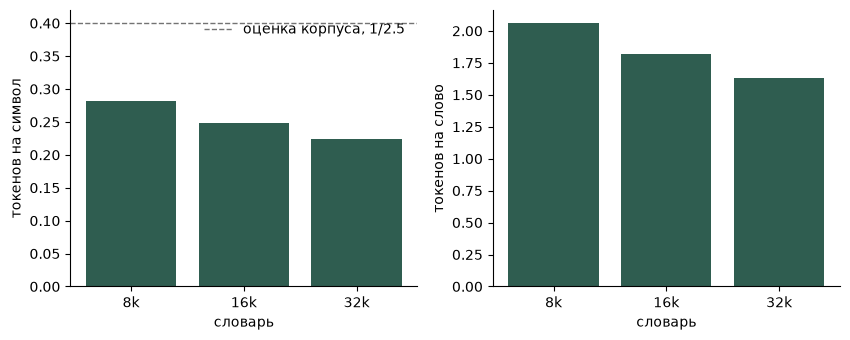

In [13]:
labels = [f"{size // 1000}k" for size in VOCAB_SIZES]
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.5))
axes[0].bar(labels, [row["токенов на символ"] for row in records], color="#2f5d50")
axes[0].axhline(1 / CHARS_PER_TOKEN, color="0.45", ls="--", lw=1, label="оценка корпуса, 1/2.5")
axes[0].set_ylabel("токенов на символ")
axes[0].legend(frameon=False)
axes[1].bar(labels, [row["токенов на слово"] for row in records], color="#2f5d50")
axes[1].set_ylabel("токенов на слово")
for axis in axes:
    axis.set_xlabel("словарь")
fig.tight_layout()
plt.show()


## Фиксация

В `CHOSEN` стоит базовый `bpe-16000`. Его стоит сменить, если таблица и проба показывают другой размер: последовательности заметно короче, а словоформы, имена и числа не рассыпаются на байты. Колонка эмбеддинга — цена словаря при ширине модели 512: для модели на 50–100M это 4.1M, 8.2M и 16.4M параметров только на матрице эмбеддинга.

Пока `FREEZE` выключен, ячейка ничего не записывает. После просмотра таблицы включите его и запустите ячейку ещё раз. Она копирует выбранный токенизатор в `tokenizers/fineweb2_rus_v001/chosen/`. Другой размер или другой снимок корпуса туда не запишутся, пока `OVERWRITE_CHOSEN` выключен. После начала обучения модели этот каталог менять нельзя.

Пока нет полного манифеста, `chosen/` не пишется даже при `ALLOW_PARTIAL`.


In [15]:
FREEZE = True
CHOSEN = "bpe-16000"
OVERWRITE_CHOSEN = False

if not FREEZE:
    print("Фиксация выключена. После таблицы выставьте CHOSEN, поставьте FREEZE = True и запустите ячейку снова.")
elif CHOSEN not in variants:
    raise KeyError(f"Нет варианта {CHOSEN}. Доступны: {', '.join(variants)}")
elif not complete:
    raise RuntimeError(
        "Корпус ещё без manifest.json. Промежуточные словари лежат рядом с обучением, "
        "chosen/ будет записан на полном снимке."
    )
else:
    chosen_dir = OUT_DIR / "chosen"
    marker = chosen_dir / "choice.json"
    if marker.exists() and not OVERWRITE_CHOSEN:
        previous = json.loads(marker.read_text(encoding="utf-8"))
        same_choice = previous.get("name") == CHOSEN
        same_corpus = previous.get("corpus", {}).get("fingerprint") == fingerprint
        if not (same_choice and same_corpus):
            raise RuntimeError(
                "В chosen/ уже записан другой выбор или другой снимок корпуса. "
                "OVERWRITE_CHOSEN = True заменяет его. После старта обучения модели этого делать нельзя."
            )
    export_tokenizer(variants[CHOSEN], chosen_dir)
    choice = {
        "name": CHOSEN,
        "vocab_size": variants[CHOSEN].get_vocab_size(),
        "algorithm": "byte-level-bpe",
        "normalizer": "NFC",
        "special_tokens": list(SPECIAL_TOKENS),
        "eos_token": EOS,
        "pad_token": EOS,
        "frozen_at": now_iso(),
        "load": "AutoTokenizer.from_pretrained('tokenizers/fineweb2_rus_v001/chosen')",
        "corpus": {
            "path": "data/fineweb2/rus_Cyrl/v001",
            "revision": revision,
            "complete": complete,
            "parts": len(fingerprint),
            "docs": train_meta["docs"],
            "chars": train_meta["chars"],
            "fingerprint": fingerprint,
        },
        "eval": {
            "docs": len(sample),
            "seed": SEED,
            "nfc_changed_docs": nfc_changed,
            "chars_per_token_planning_estimate": CHARS_PER_TOKEN,
            "metrics": records,
        },
        "warning": "После начала обучения модели нельзя менять соответствие id и токенов.",
    }
    marker.write_text(json.dumps(choice, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"зафиксирован {CHOSEN}: {chosen_dir.relative_to(ROOT)}")
    print("Дальше в обучение модели берётся этот каталог. Id токенов больше не меняются.")


зафиксирован bpe-16000: tokenizers/fineweb2_rus_v001/chosen
Дальше в обучение модели берётся этот каталог. Id токенов больше не меняются.
